In [ ]:
import sys
sys.path.insert(0,'../CRLDenv/lib/python3.11/site-packages')
print(sys.path)

['../CRLDenv/lib/python3.11/site-packages', '/home/clemence/Documents/PhD/Code/DistRLdynamics', '/usr/lib/python39.zip', '/usr/lib/python3.9', '/usr/lib/python3.9/lib-dynload', '', '/home/clemence/Documents/PhD/Code/pyCRLD/CRLDenv/lib/python3.9/site-packages']


In [ ]:
import numpy as np
from scipy.stats import norm

import jax.numpy as jnp
from jax import jit
from functools import partial

from pyCRLD.Agents.Base import abase
from pyCRLD.Utils.Helpers import *

import pandas as pd
# import seaborn as sns

In [ ]:
from pyCRLD.Environments.SocialDilemma import SocialDilemma
from pyCRLD.Environments.RiskRewardDilemma import RiskRewardDilemma
from pyCRLD.Environments.DistTwoArmedBanditOneState import DistTwoArmedBanditOneState
from pyCRLD.Agents.StrategySARSA import stratSARSA
from qBaseDistR import qbaseDist
from qBaseSARSA import qbaseSARSA
from pyCRLD.Utils.Trajectories1D import trajectories_1D 
from pyCRLD.Utils.PhasePlot import phaseplot
import matplotlib.pyplot as plt

In [ ]:
import matplotlib as mpl
from pyCRLD.Utils.PhasePlot import phaseplot, _data_to_plot, _strategies, _dXisa_s

In [ ]:
def _data_diagonal(mae,  # CRLD multi-agent environment object
                   res,  # range & resolution of flow arrows 
                   xinds:tuple,  # of indices of the phase space object to plot along the x axis
                   traj_len:int,  # trajectory len
                   # NrRandom:int,  # how many random (in the other dimensions) stratgies for averaging 
                   # difffunc:Callable,  # to compute which kind of arrows to plot (RPE or dX)
                   phasespace_items,  # to obtain phase space items for one ax plot point
                   verbose=False  # shall I talk to you while working?
                   ):
        
    l = len(res)
    RPEs = np.zeros((mae.Z, l))
    dXs = np.zeros((mae.Z, l))

    for i in range(mae.Z):
        for j, xval in enumerate(res):
            X = _diagonal(mae, xinds, xval)  # generate random strategies to average over
            prederror = mae.TDerror(X, norm=True) # compute pred error
            RPEs[i, j] = prederror[xinds[0], i, xinds[2]]  # pred error for indices of interest
            dX = mae.step(X)[0] - X
            dXs[i, j] = dX[xinds[0], i, xinds[2]]  # dX for indices of interest
            
    return RPEs, dXs


def _diagonal(mae,  # CRLD multi-agent environment object
              xinds:tuple,  # of indices of the phase space item to plot along the x axis
              xval:float,  # the value of the phase space item to plot along the x axis
              ):  # how many random (in the other dimensions) stratgies for averaging
    
    N, C, M = mae.N, mae.Q, mae.M  # Number of agents, conditions, actions
    # Xs = np.random.rand(NrRandom, N, C, M)  # random policies
    Xs = np.zeros((N, C, M))
    
    xi, xc, xa = xinds; xa_ = tuple(set(range(M)) - set([xa]))
    
    Xs[xi, xc, xa] = xval  # setting x and y values
    
    # normalisation
    Xs[xi,xc,xa_] = 1-Xs[xi, xc, xa]
    
    if C > 1:
        xc_ = tuple(set(range(C)) - set([xc]))
        Xs[xi, xc_, xa] = 1  # setting x and y values
        Xs[xi, xc_, xa_] = 1 - Xs[xi, xc_, xa]
    if N > 1:
        xi_ = tuple(set(range(N)) - set([xi]))
        Xs[xi_, xc, xa] = xval  # setting x and y values
        Xs[xi_, xc, xa_] = 1 - Xs[xi_, xc, xa]
    
    return Xs


def reward_traj(mae,  # CRLD multi-agent environment object
                X:tuple,  # strategy
                i,  # agent
                NrRandom:int=3,  # how many random (in the other dimensions) stratgies for averaging 
                traj_len:int=500,  # trajectory length
                ): 
    
    # x axis
    r_traj = np.zeros((traj_len))
    traj, fpreached = mae.trajectory(X, traj_len) # compute trajectory
    for t in range(traj_len):
        r_traj[t] = mae.Ri(traj[t,...])[i]
    return traj, r_traj
    

def compare_levels(env,
                   level_list,  # level list
                   method,  # used method
                   gamma,
                   beta,
                   Rmin,
                   Rmax,
                   x:tuple,  # which phase space axes to plot along x axes
                   res,  # specify range & resolution
                   nrb:int=29,
                   discsig:float=0.05,
                   lr:float=0.1,
                   traj_len:int=500,  # trajectory length
                   cmap='viridis',  # Colormap
                   acts=None,  # Action descriptions
                   conds=None,  # Conditions descriptions 
                   axes=None,  # Axes to plot into
                   verbose=False,  # shall I talk to you while working?
                   ):  
   

    # Fig and Axes
    states = 1
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(4.5 * 3.8, 3.8))
    cmap = mpl.cm.get_cmap(cmap)
    ext = np.linspace(0, 1, len(level_list))
    colors = cmap(tuple(ext))
    
    # x axis
    xs = res
    zero = np.zeros((len(xs)))

    # The Plots
    for j, l in enumerate(level_list):
        print(l)
        if method=='weights':
            mae = qbaseSARSA(env, nr_reward_bins=nrb, discretization_sigma=discsig, 
                             learning_rates=lr, discount_factors=gamma, 
                             choice_intensities=beta, Rmin=Rmin, Rmax=Rmax,
                             method=method, wU=l, use_prefactor=True)
                             
        elif method=='expectile':
            mae = qbaseSARSA(env, nr_reward_bins=nrb, discretization_sigma=discsig, 
                             learning_rates=lr, discount_factors=gamma, 
                             choice_intensities=beta, Rmin=Rmin, Rmax=Rmax,
                             method=method, tau=l, use_prefactor=True)
            
        xinds = (x[0][0], x[1][0], x[2][0])  # fix this later
 
        # obtain the data to plot
        RPEs, dXs = _data_diagonal(mae, res, xinds, traj_len,
                                   phasespace_items=_diagonal, verbose=verbose)
        ax1.plot(xs, dXs[0, :], color=colors[j], label=r'$\tau=$'+str(l))
        ax1.plot(xs, zero, color="grey", ls='dashed')
        
        # obtain reward traj
        X0 = np.ones((mae.N, mae.Z, mae.M)) * 0.5
        X_traj, r_traj = reward_traj(mae, X0, 0, traj_len=traj_len)
        ax2.plot(np.arange(0, traj_len), r_traj, color=colors[j], label=r'$\tau=$'+str(l))
        ax3.plot(np.arange(0, traj_len), X_traj[:,0,0,0], color=colors[j], label=r'$\tau=$'+str(l))
        
    ax1.set_ylabel(r"$dX$")
    ax1.set_xlabel(r'$X^{0}_{00}$')
    ax2.set_xlabel('time step')
    ax2.set_title('mean reward obtained by agent 0 over time')
    ax3.set_title('prob. agent 0 state 0 action 0')
    ax1.set_title('phase plot')
    ax3.legend(bbox_to_anchor=(1.01, 1.01))
    
    # return fig

In [ ]:
env = RiskRewardDilemma(pc=0.1, pr=0.2, rc=0.5, rr=1, rd=0)

In [ ]:
mae = qbaseSARSA(env, nr_reward_bins=29, discretization_sigma=0.05, 
                 learning_rates=0.1, discount_factors=0.9, 
                 choice_intensities=50, Rmin=0, Rmax=1,
                 method="expectile", tau=0.7, use_prefactor=True)

No GPU/TPU found, falling back to CPU. (Set TF_CPP_MIN_LOG_LEVEL=0 and rerun for more info.)


In [ ]:
w = jnp.ones((mae.N, mae.Z, mae.M, len(mae.gridpoints)))
n = jnp.newaxis
w.shape

(1, 2, 2, 29)

In [ ]:
X = np.ones((1, 2, 2))
X[0, :, 0] = 0.45
X[0, :, 1] = 1 - X[0, :, 0]
Qq = mae.Qisaq(X)
Q = jnp.einsum('ijkl,l->ijk', Qq, mae.gridpoints)

In [ ]:
upper = mae.gridpoints[n,n,n,:] >= Q[:,:,:,n]

In [ ]:
mae.gridpoints

array([0.        , 0.03571429, 0.07142857, 0.10714286, 0.14285714,
       0.17857143, 0.21428571, 0.25      , 0.28571429, 0.32142857,
       0.35714286, 0.39285714, 0.42857143, 0.46428571, 0.5       ,
       0.53571429, 0.57142857, 0.60714286, 0.64285714, 0.67857143,
       0.71428571, 0.75      , 0.78571429, 0.82142857, 0.85714286,
       0.89285714, 0.92857143, 0.96428571, 1.        ])

In [ ]:
Q[0, 0, 1]

Array(0.38608584, dtype=float32)

In [ ]:
np.sum(1 - upper[0, 0, 1, :])

Array(11, dtype=int32)

In [ ]:
upper = upper * (mae.wU - 1)
upper

Array([[[[ 0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,
           0. ,  0. ,  0. ,  0. , -0.9, -0.9, -0.9, -0.9, -0.9, -0.9,
          -0.9, -0.9, -0.9, -0.9, -0.9, -0.9, -0.9, -0.9, -0.9],
         [ 0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,
           0. ,  0. ,  0. , -0.9, -0.9, -0.9, -0.9, -0.9, -0.9, -0.9,
          -0.9, -0.9, -0.9, -0.9, -0.9, -0.9, -0.9, -0.9, -0.9]],

        [[ 0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. , -0.9, -0.9, -0.9,
          -0.9, -0.9, -0.9, -0.9, -0.9, -0.9, -0.9, -0.9, -0.9, -0.9,
          -0.9, -0.9, -0.9, -0.9, -0.9, -0.9, -0.9, -0.9, -0.9],
         [ 0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. , -0.9, -0.9, -0.9,
          -0.9, -0.9, -0.9, -0.9, -0.9, -0.9, -0.9, -0.9, -0.9, -0.9,
          -0.9, -0.9, -0.9, -0.9, -0.9, -0.9, -0.9, -0.9, -0.9]]]],      dtype=float32, weak_type=True)

In [ ]:
w = w + upper
w

Array([[[[1.        , 1.        , 1.        , 1.        , 1.        ,
          1.        , 1.        , 1.        , 1.        , 1.        ,
          1.        , 1.        , 1.        , 1.        , 0.10000002,
          0.10000002, 0.10000002, 0.10000002, 0.10000002, 0.10000002,
          0.10000002, 0.10000002, 0.10000002, 0.10000002, 0.10000002,
          0.10000002, 0.10000002, 0.10000002, 0.10000002],
         [1.        , 1.        , 1.        , 1.        , 1.        ,
          1.        , 1.        , 1.        , 1.        , 1.        ,
          1.        , 1.        , 1.        , 0.10000002, 0.10000002,
          0.10000002, 0.10000002, 0.10000002, 0.10000002, 0.10000002,
          0.10000002, 0.10000002, 0.10000002, 0.10000002, 0.10000002,
          0.10000002, 0.10000002, 0.10000002, 0.10000002]],

        [[1.        , 1.        , 1.        , 1.        , 1.        ,
          1.        , 1.        , 0.10000002, 0.10000002, 0.10000002,
          0.10000002, 0.10000002, 0.1000

In [ ]:
nQq = w * Qq
norm = jnp.sum(nQq, axis=-1)  
norm = jnp.repeat(norm[..., jnp.newaxis], len(mae.gridpoints), axis=-1)
nQq = nQq / norm
nQq.sum(axis=-1)

Array([[[1.        , 0.99999994],
        [0.9999998 , 0.9999999 ]]], dtype=float32)

<BarContainer object of 29 artists>

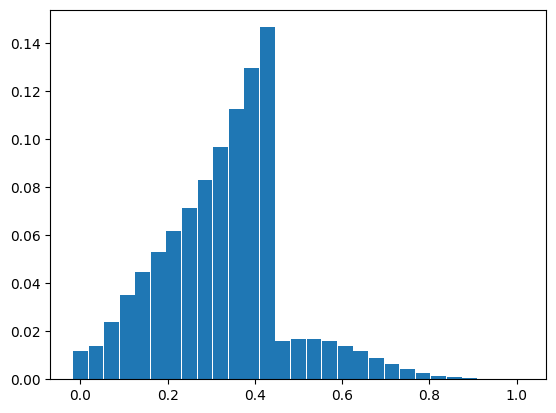

In [ ]:
plt.bar(mae.gridpoints, nQq[0, 0, 1, :], width = .95*mae.gridwidth)

<BarContainer object of 29 artists>

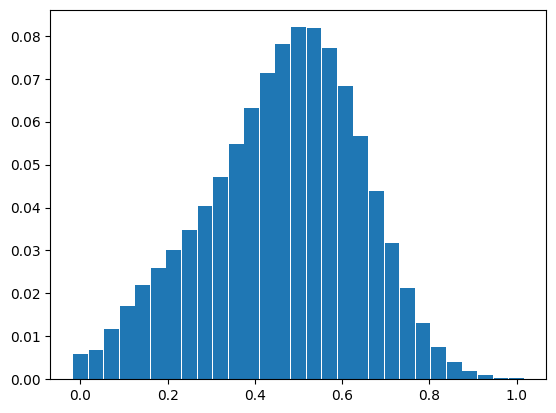

In [ ]:
plt.bar(mae.gridpoints, Qq[0, 0, 1, :], width = .95*mae.gridwidth)

In [ ]:
nQ = jnp.einsum('ijkl,l->ijk', nQq, mae.gridpoints)
Q, nQ

(Array([[[0.47251976, 0.46211734],
         [0.24946843, 0.23001087]]], dtype=float32),
 Array([[[0.37413755, 0.32998866],
         [0.13255528, 0.12681736]]], dtype=float32))

In [ ]:
mae._Qisa(X)

Array([[[0.27411282, 0.2490276 ],
        [0.0938414 , 0.07897009]]], dtype=float32)

In [ ]:
mae.Qisa(X)

Array([[[0.26889634, 0.26862097],
        [0.08987822, 0.07532603]]], dtype=float32)

In [ ]:
Xs = np.linspace(0, 1, 21)
Xs[0] = 0.001
Xs[-1] = 0.999
Qs = np.zeros((len(Xs)))
Q1s = np.zeros((len(Xs)))
wQs = np.zeros((len(Xs)))
wQ1s = np.zeros((len(Xs)))
for i, x in enumerate(Xs):
    Xisa = np.zeros((1, 2, 2))
    Xisa[0, :, 0] = x
    Xisa[0, :, 1] = 1 - x
    Qs[i] = np.dot(mae.Qisaq(Xisa)[0, 0, 0, :], mae.gridpoints) #- mae.Qisa(Xisa)[0, 0, 0]
    Q1s[i] = np.dot(mae.Qisaq(Xisa)[0, 0, 1, :], mae.gridpoints)
    wQs[i] = mae._Qisa(Xisa)[0, 0, 0] #- mae._Qisa(Xisa)[0, 0, 0]
    wQ1s[i] = mae._Qisa(Xisa)[0, 0, 1]

[<matplotlib.lines.Line2D>]

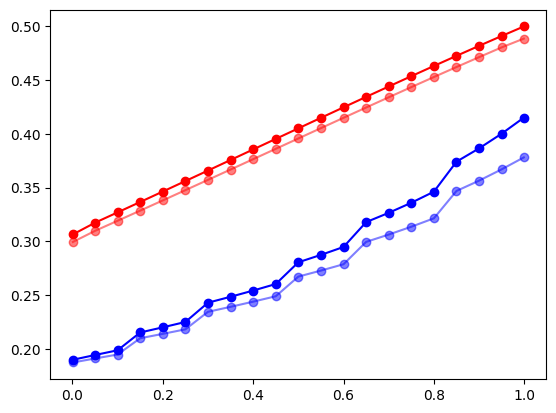

In [ ]:
plt.plot(Xs, wQs, 'o-', color='blue')
plt.plot(Xs, wQ1s, 'o-', color='blue', alpha=0.5)
plt.plot(Xs, Qs, 'o-', color='red')
plt.plot(Xs, Q1s, 'o-', color='red', alpha=0.5)

In [ ]:
wQisaq = weights(w, Qisaq, gpoints)
_Qisa = jnp.einsum('ijkl,l->ijk', wQisaq, gpoints)  # take the new distrib's mean

In [ ]:
weights = np.array([0.1, 0.4, 0.7, 1, 4, 7, 10])

x = ([0], [0], [0])  # probability of being cautious in the prosperous state
res = np.linspace(0, 1., 21)
res[0] = 0.0001
res[-1] = 0.9999

/tmp/ipykernel_6946/3603873359.py:93: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = mpl.cm.get_cmap(cmap)


0.1
0.4
0.7
1.0
4.0
7.0
10.0


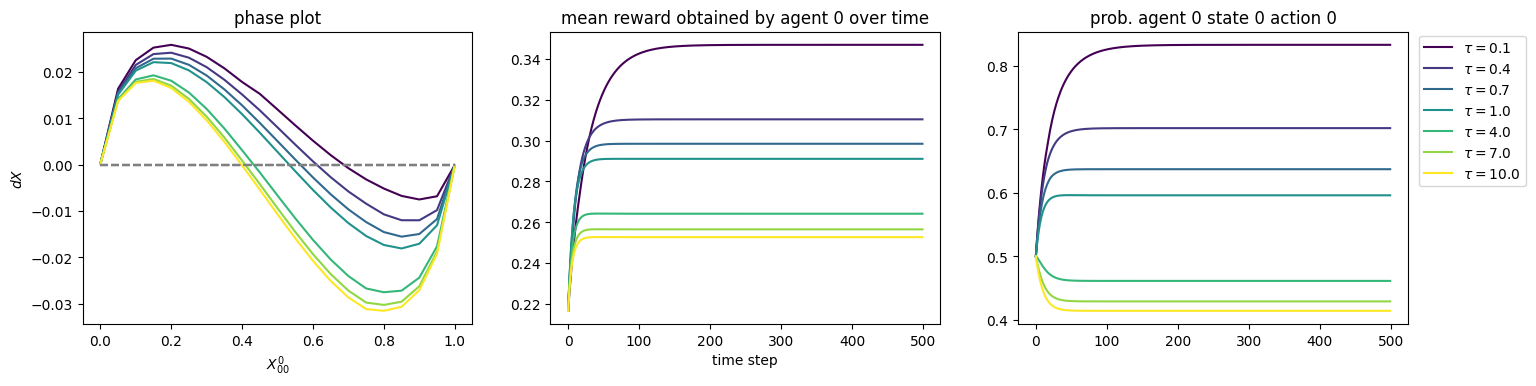

In [ ]:
compare_levels(env, weights, method='weights', gamma=0.9, beta=50, Rmin=0, Rmax=1, 
               x=x, res=res, nrb=29, discsig=0.05)

In [ ]:
expectiles = np.array([0.3, 0.5, 0.7])

x = ([0], [0], [0])  # probability of being cautious in the prosperous state
res = np.linspace(0, 1., 21)
res[0] = 0.0001
res[-1] = 0.9999

/tmp/ipykernel_6946/737832691.py:92: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = mpl.cm.get_cmap(cmap)


0.3
0.5
0.7


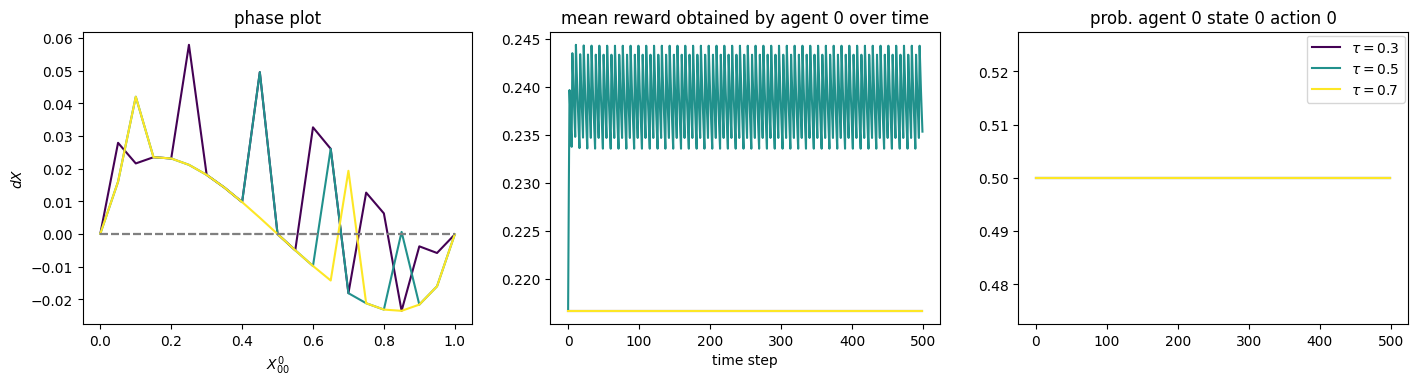

In [ ]:
compare_levels(env, expectiles, method='expectile', gamma=0.9, beta=50, Rmin=0, Rmax=1, 
               x=x, res=res, nrb=29, discsig=0.05)

In [ ]:
env = RiskRewardDilemma(pc=0.1, pr=0.2, rc=2, rr=4, rd=0)

In [ ]:
expectiles = np.array([0.3, 0.5, 0.7])

x = ([0], [0], [0])  # probability of being cautious in the prosperous state
res = np.linspace(0, 1., 21)
res[0] = 0.0001
res[-1] = 0.9999

/tmp/ipykernel_7926/3603873359.py:93: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = mpl.cm.get_cmap(cmap)


0.3


No GPU/TPU found, falling back to CPU. (Set TF_CPP_MIN_LOG_LEVEL=0 and rerun for more info.)


0.5
0.7


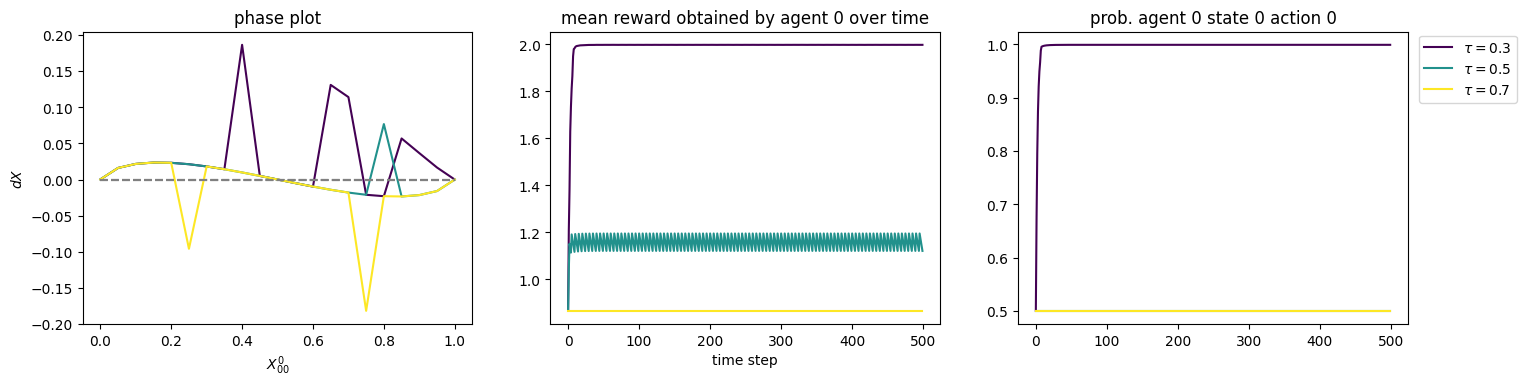

In [ ]:
compare_levels(env, expectiles, method='expectile', gamma=0.9, beta=50, Rmin=0, Rmax=4, 
               x=x, res=res, nrb=29, discsig=0.05)

In [ ]:
env = SocialDilemma(R=3, S=-2, T=1, P=0)

/tmp/ipykernel_7926/3603873359.py:93: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = mpl.cm.get_cmap(cmap)


0.3
0.5
0.7


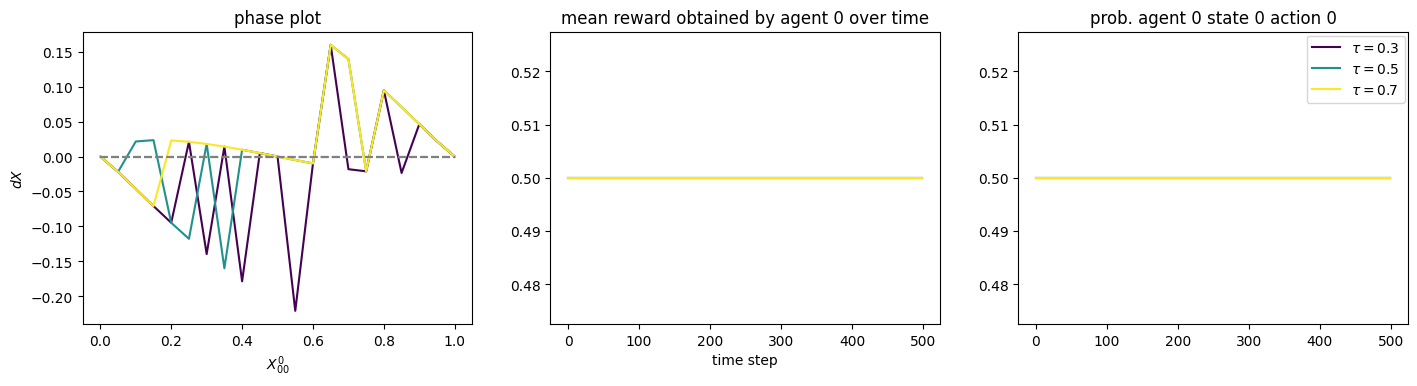

In [ ]:
compare_levels(env, expectiles, method='expectile', gamma=0.9, beta=50, Rmin=-2, Rmax=3, 
               x=x, res=res, nrb=29, discsig=0.05)

In [ ]:
mae = qbaseSARSA(env, nr_reward_bins=29, discretization_sigma=0.05, 
                 learning_rates=0.1, discount_factors=0.9, 
                 choice_intensities=50, Rmin=0, Rmax=1,
                 method="expectile", tau=0.7, use_prefactor=True)

In [ ]:
Xs = np.linspace(0, 1, 21)
Xs[0] = 0.001
Xs[-1] = 0.999
Qs = np.zeros((len(Xs)))
Q1s = np.zeros((len(Xs)))
wQs = np.zeros((len(Xs)))
wQ1s = np.zeros((len(Xs)))
for i, x in enumerate(Xs):
    Xisa = np.zeros((1, 2, 2))
    Xisa[0, :, 0] = x
    Xisa[0, :, 1] = 1 - x
    Qs[i] = np.dot(mae.Qisaq(Xisa)[0, 0, 0, :], mae.gridpoints) #- mae.Qisa(Xisa)[0, 0, 0]
    Q1s[i] = np.dot(mae.Qisaq(Xisa)[0, 0, 1, :], mae.gridpoints)
    wQs[i] = mae._Qisa(Xisa)[0, 0, 0] #- mae._Qisa(Xisa)[0, 0, 0]
    wQ1s[i] = mae._Qisa(Xisa)[0, 0, 1]

[<matplotlib.lines.Line2D>]

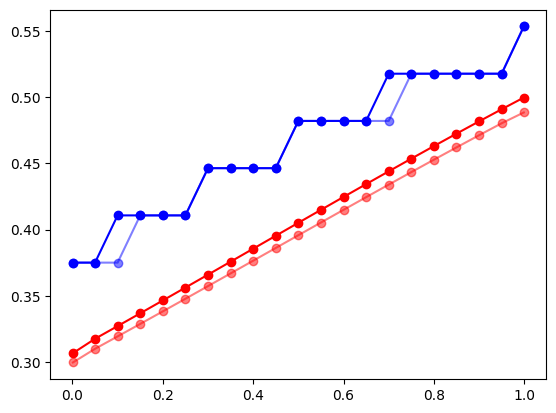

In [ ]:
plt.plot(Xs, wQs, 'o-', color='blue')
plt.plot(Xs, wQ1s, 'o-', color='blue', alpha=0.5)
plt.plot(Xs, Qs, 'o-', color='red')
plt.plot(Xs, Q1s, 'o-', color='red', alpha=0.5)

In [ ]:
def stepnorm(mae,
             Xisa  # Joint strategy
             ):  # (Updated joint strategy, Prediction error)
        TDe = mae.TDerror(Xisa, norm=True)
        n = jnp.newaxis
        XexpaTDe = Xisa * jnp.exp(mae.alpha[:,n,n] * TDe)
        return XexpaTDe / XexpaTDe.sum(-1, keepdims=True), TDe

In [ ]:
res = np.linspace(0, 1., 21)
res[0] = 0.0001
res[-1] = 0.9999

Xs = np.zeros((1, 2, 2, len(res)))
Xs[0, 0, 0, :] = res
Xs[0, 1, 0, :] = res
Xs[0, :, 1, :] = 1 - Xs[0, :, 0, :]

mae = qbaseSARSA(env, nr_reward_bins=29, discretization_sigma=0.05, 
                 learning_rates=0.1, discount_factors=0.9, 
                 choice_intensities=50, Rmin=0, Rmax=1,
                 method="weights", wU=10, use_prefactor=True)

In [ ]:
dXs = np.zeros((1, 2, 2, len(res)))
dXs_f = np.zeros((1, 2, 2, len(res)))
for i in range(len(res)):
    dXs[:, :, :, i] = stepnorm(mae, Xs[...,i])[0] - Xs[...,i]
    dXs_f[:, :, :, i] = mae.step(Xs[...,i])[0] - Xs[...,i]

[<matplotlib.lines.Line2D>]

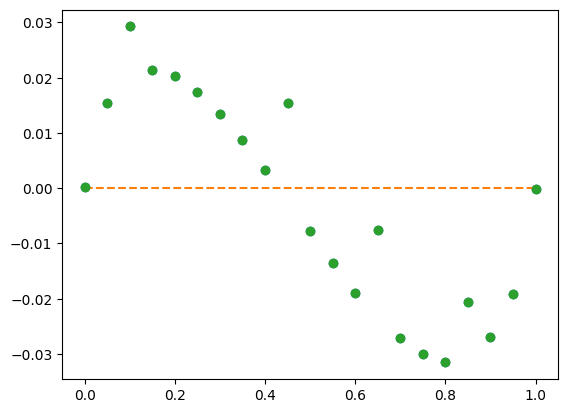

In [ ]:
plt.plot(Xs[0, 0, 0, :], dXs[0, 0, 0, :], 'o')
plt.plot(Xs[0, 0, 0, :], np.zeros((len(res))), '--')
plt.plot(Xs[0, 0, 0, :], dXs_f[0, 0, 0, :], 'o')

In [ ]:
Xisa = np.zeros((1, 2, 2))
Xisa[0, :, 0] = 0.85
Xisa[0, :, 1] = 1 - Xisa[0, :, 0]

In [ ]:
Xt1 = np.zeros((1, 2, 2))
Xt1[0, :, 0] = 0.9
Xt1[0, :, 1] = 1 - Xt1[0, :, 0]

In [ ]:
Qisaq = mae.Qisaq(Xisa)
wQisa = mae._Qisa(Xisa)

In [ ]:
Qt1 = mae.Qisaq(Xt1)
wQt1 = mae._Qisa(Xt1)
m = np.dot(mae.gridpoints, Qisaq[0,0,0,:])

[<matplotlib.lines.Line2D>]

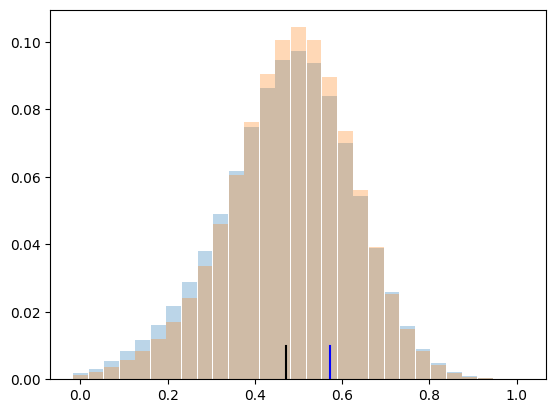

In [ ]:
plt.bar(mae.gridpoints, Qisaq[0, 0, 0, :], width=.95*mae.gridwidth, alpha=0.3)
plt.bar(mae.gridpoints, Qt1[0, 0, 0, :], width=.95*mae.gridwidth, alpha=0.3)
plt.plot([wQisa[0,0,0], wQisa[0,0,0]], [0, 0.01], color='blue')
# plt.plot([wQt1[0,0,0], wQt1[0,0,0]], [0, 0.01], color='red')
plt.plot([m, m], [0, 0.01], color='black')

In [ ]:
env = SocialDilemma(R=3, S=-2, T=1, P=0)

In [ ]:
weights = np.array([0.1, 0.4, 0.7, 1, 4, 7, 10])

x = ([0], [0], [0])  # probability of being cautious in the prosperous state
res = np.linspace(0, 1., 21)
res[0] = 0.0001
res[-1] = 0.9999

/tmp/ipykernel_6946/737832691.py:92: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = mpl.cm.get_cmap(cmap)


0.1
0.4
0.7
1.0
4.0
7.0
10.0


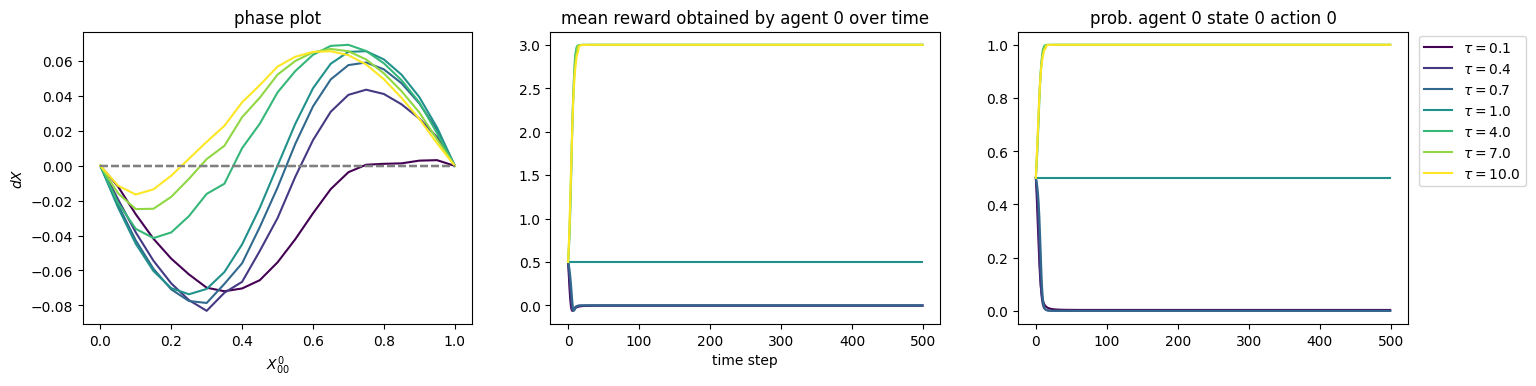

In [ ]:
compare_levels(env, weights, method='weights', gamma=0.9, beta=50, Rmin=-2, Rmax=3, x=x, res=res, nrb=23)

In [ ]:
mae = qbaseSARSA(env, nr_reward_bins=29, discretization_sigma=0.05, 
                 learning_rates=0.1, discount_factors=0.9, 
                 choice_intensities=50, Rmin=-2, Rmax=3,
                 method="weights", wU=4, use_prefactor=True)

In [ ]:
Xs = np.linspace(0, 1, 21)
Xs[0] = 0.001
Xs[-1] = 0.999
Qs = np.zeros((len(Xs)))
Q1s = np.zeros((len(Xs)))
wQs = np.zeros((len(Xs)))
wQ1s = np.zeros((len(Xs)))
for i, x in enumerate(Xs):
    Xisa = np.zeros((2, 1, 2))
    Xisa[:, 0, 0] = x
    Xisa[:, 0, 1] = 1 - x
    Qs[i] = np.dot(mae.Qisaq(Xisa)[0, 0, 0, :], mae.gridpoints) #- mae.Qisa(Xisa)[0, 0, 0]
    Q1s[i] = np.dot(mae.Qisaq(Xisa)[0, 0, 1, :], mae.gridpoints)
    wQs[i] = mae._Qisa(Xisa)[0, 0, 0] #- mae._Qisa(Xisa)[0, 0, 0]
    wQ1s[i] = mae._Qisa(Xisa)[0, 0, 1]

[<matplotlib.lines.Line2D>]

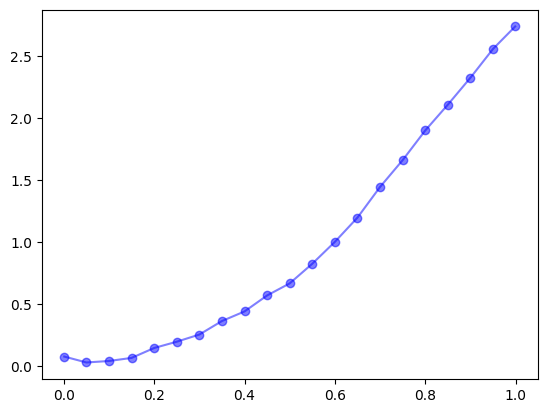

In [ ]:
# plt.plot(Xs, wQs, 'o-', color='blue')
plt.plot(Xs, wQ1s, 'o-', color='blue', alpha=0.5)
# plt.plot(Xs, Qs, 'o-', color='red')
# plt.plot(Xs, Q1s, 'o-', color='red', alpha=0.5)

In [ ]:
w = jnp.ones((mae.N, mae.Z, mae.M, len(mae.gridpoints)))
n = jnp.newaxis
w.shape

(2, 1, 2, 29)

In [ ]:
X = np.ones((2, 1, 2))
X[:, 0, 0] = 0.2
X[:, 0, 1] = 1 - X[:, 0, 0]
Qq = mae.Qisaq(X)
Q = jnp.einsum('ijkl,l->ijk', Qq, mae.gridpoints)

In [ ]:
upper = mae.gridpoints[n,n,n,:] >= Q[:,:,:,n]

In [ ]:
mae.gridpoints

array([-2.        , -1.82142857, -1.64285714, -1.46428571, -1.28571429,
       -1.10714286, -0.92857143, -0.75      , -0.57142857, -0.39285714,
       -0.21428571, -0.03571429,  0.14285714,  0.32142857,  0.5       ,
        0.67857143,  0.85714286,  1.03571429,  1.21428571,  1.39285714,
        1.57142857,  1.75      ,  1.92857143,  2.10714286,  2.28571429,
        2.46428571,  2.64285714,  2.82142857,  3.        ])

In [ ]:
Q[0, 0, 0]

Array(-0.12555054, dtype=float32)

In [ ]:
np.sum(1 - upper[0, 0, 0, :])

Array(11, dtype=int32)

In [ ]:
env = SocialDilemma(R=1, S=-2, T=3, P=0)

In [ ]:
x = ([0], [0], [0])  # probability of cooperating for agent 1
res = np.linspace(0, 1., 21)
res[0] = 0.0001
res[-1] = 0.9999

/tmp/ipykernel_16550/737832691.py:92: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = mpl.cm.get_cmap(cmap)


0.1
0.4
0.7
1.0
4.0
7.0
10.0


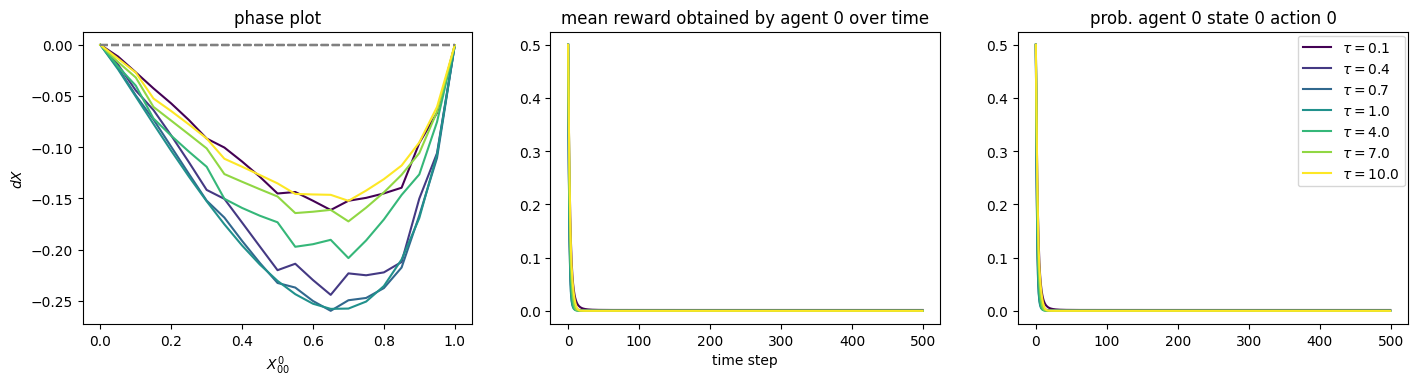

In [ ]:
compare_levels(env, weights, method='weights', gamma=0.9, beta=50, Rmin=-2, Rmax=3, x=x, res=res)